In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [5]:
# 2. Carrega o dataset
arquivo_csv = "Fiap On - Fase 6 - Geolocalização Dataset - Asset.csv"
df_logistica = pd.read_csv(arquivo_csv)

# 3. Tratamento correto (sem inplace=True, atribuindo o resultado de volta)
print(f"Linhas antes da limpeza: {len(df_logistica)}")
df_logistica = df_logistica.dropna()
print(f"Linhas após remover nulos: {len(df_logistica)}")

# Exibe as primeiras linhas para conferir
display(df_logistica.head(3))

Linhas antes da limpeza: 653
Linhas após remover nulos: 653


,latitude,longitude,price
0,"-21,591360","-51,066690","52,47"
1,"-21,285350","-49,654970","37,03"
2,"-22,025900","-47,067020","71,50"


In [ ]:
# 1. Converte latitude, longitude e TAMBÉM o price (que estava com vírgula) para números com ponto (float)
df_logistica['latitude'] = df_logistica['latitude'].astype(str).str.replace(',', '.').astype(float)
df_logistica['longitude'] = df_logistica['longitude'].astype(str).str.replace(',', '.').astype(float)
df_logistica['price'] = df_logistica['price'].astype(str).str.replace(',', '.').astype(float)

# 2. Define a quantidade de centros de distribuição (K)
k_otimo = 5

# 3. Seleciona as colunas para a clusterização
X = df_logistica[['latitude', 'longitude']]

# 4. Executa o algoritmo K-Means
kmeans = KMeans(n_clusters=k_otimo, random_state=42, n_init=10)
df_logistica['Cluster'] = kmeans.fit_predict(X)

# Coordenadas dos centroides (localização sugerida para os novos hubs)
centroides = kmeans.cluster_centers_

# 5. Calcula o valor total atendido por cada centro (agora sim com a soma matemática correta)
valor_por_centro = df_logistica.groupby('Cluster')['price'].sum().reset_index()
valor_por_centro.columns = ['Centro_ID', 'Valor_Total_Atendido']

# Formata o valor monetário com 2 casas decimais para exibição limpa (ex: R$ 1.500,00)
valor_por_centro['Valor_Total_Atendido'] = valor_por_centro['Valor_Total_Atendido'].apply(lambda x: f"R$ {x:,.2f}")

print("=== VALOR FINANCEIRO TOTAL ATENDIDO POR CENTRO DE RETIRADA ===")
print(valor_por_centro.to_string(index=False))

=== VALOR FINANCEIRO TOTAL ATENDIDO POR CENTRO DE RETIRADA ===
 Centro_ID Valor_Total_Atendido
         0          R$ 7,794.24
         1         R$ 10,246.94
         2          R$ 7,020.18
         3          R$ 7,660.93
         4          R$ 8,461.52


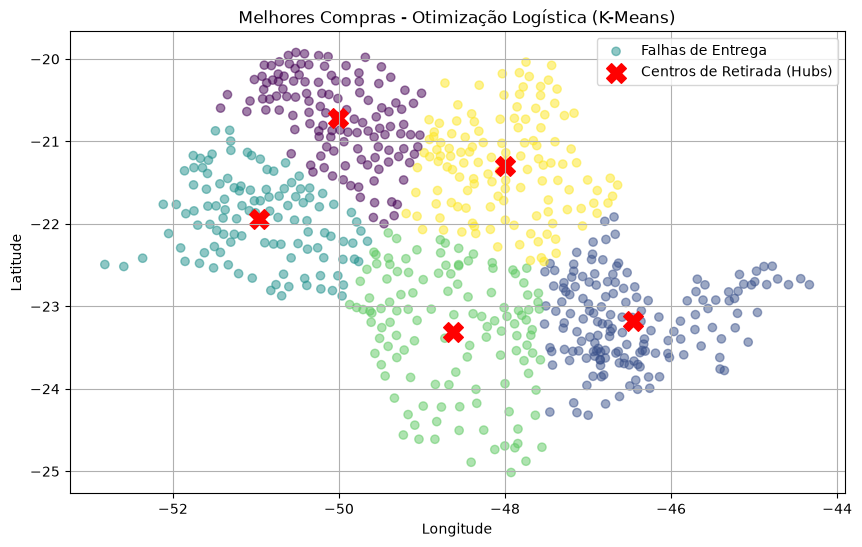

In [9]:
plt.figure(figsize=(10, 6))

# Plota os pontos de entrega originais coloridos por cluster
plt.scatter(
    df_logistica['longitude'], 
    df_logistica['latitude'], 
    c=df_logistica['Cluster'], 
    cmap='viridis', 
    alpha=0.5, 
    label='Falhas de Entrega'
)

# Plota os centroides (os 5 novos centros de retirada)
plt.scatter(
    centroides[:, 1], 
    centroides[:, 0], 
    c='red', 
    marker='X', 
    s=200, 
    label='Centros de Retirada (Hubs)'
)

plt.title('Melhores Compras - Otimização Logística (K-Means)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True)
plt.show()